# Residual correlations of growth traits in Madura cattle

This R notebook audits the records, adjusts measurements, imputes residuals, defines analysis cohorts, estimates correlations, and produces GGally figures.

The study cutoff was **30 September 2026**. The four traits are body weight (BB, kg), body length (PB, cm), body height (TB, cm), and chest girth (LD, cm). The recording stages are birth, 6 months, 1 year, and 18 months. Plots display residuals on each trait's measurement scale.

Within-stage correlations use animals with all four residuals available at that stage after imputation. Across-stage correlations use the same animals with all 16 trait–stage values available. Imputation predictors come from originally observed measurements.

These are descriptive residual correlations. The models exclude pedigree effects. The imputation model assumes bivariate normality and ignorable missingness conditional on the observed predictor. Trait-wise imputation does not explicitly model covariance among traits.

## 1. Setup and dependencies

Run the cells in order using an R kernel with the required packages installed.

In [2]:
project_dir <- Sys.getenv("PDU_PROJECT_DIR", "C:\\Users\\rizal\\Nextcloud2\\PDU_Julius")
stopifnot(dir.exists(project_dir))
setwd(project_dir)
local_library <- Sys.getenv("PDU_R_LIBRARY", file.path(project_dir, "R-library"))
if (dir.exists(local_library)) .libPaths(c(local_library, .libPaths()))
packages <- c("readxl", "dplyr", "tidyr", "ggplot2", "GGally")
missing_packages <- packages[!vapply(packages, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing_packages)) stop("Pasang paket terlebih dahulu: ", paste(missing_packages, collapse = ", "))
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
})
cutoff <- as.Date("2026-09-30")
seed <- 20261029L
set.seed(seed)
output_dir <- Sys.getenv("PDU_OUTPUT_DIR", file.path(project_dir, "hasil_korelasi"))
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)
source_file <- file.path(project_dir, "analysis_PDU_Sapi Madura.xlsx")
source_hash <- tools::md5sum(source_file)
traits <- c("BB", "PB", "TB", "LD")
stages <- c("Birth", "6 months", "1 year", "18 months")
months <- c(0, 6, 12, 18)
birth_limits <- as.Date(c("2026-09-30", "2026-03-30", "2025-09-30", "2025-03-30"))
columns <- list(
  c("BWB", "BLB", "WHB", "CGB"), c("BW6", "BL6", "WH6", "CG6"),
  c("BW1Y", "BL1Y", "WH1Y", "CG1Y"), c("BW18M", "BL18M", "WH18M", "CG18M")
)
date_columns <- c(NA, "Measurement_6Month", "Measurement_1years", "Measurement_18Month")
age_columns <- c(NA, "Age_6Month", "Age_1years", "Age_18Month")
raw <- readxl::read_excel(source_file, sheet = "Sheet1")
stopifnot(nrow(raw) == 300L, !anyDuplicated(as.character(raw$ID)))
print(data.frame(package = packages, version = vapply(packages, function(p) as.character(packageVersion(p)), character(1))))


        package version
readxl   readxl 1.5.0.1
dplyr     dplyr   1.1.4
tidyr     tidyr   1.3.2
ggplot2 ggplot2   4.0.1
GGally   GGally   2.4.0


## 2. Data audit and preparation

Animal ID is the matching key because AnimalKey contains repeated placeholder labels. Zero measurements are treated as missing. The study cutoff defines age eligibility and the measurement dates retained for analysis. The audit flags unusual nonzero values for review.

In [3]:
long <- bind_rows(lapply(seq_along(stages), function(j) {
  born <- as.Date(raw$Born)
  measured <- if (j == 1) born else as.Date(raw[[date_columns[j]]])
  age <- if (j == 1) rep(0, nrow(raw)) else as.numeric(raw[[age_columns[j]]])
  if (j > 1) {
    ok <- !is.na(measured) & !is.na(age)
    stopifnot(all(as.numeric(measured[ok] - born[ok]) == age[ok]))
  }
  bind_rows(lapply(seq_along(traits), function(k) {
    value <- as.numeric(raw[[columns[[j]][k]]])
    eligible <- !is.na(born) & born <= birth_limits[j]
    usable_date <- !is.na(measured) & measured <= cutoff
    data.frame(
      ID = as.character(raw$ID), AnimalKey = as.character(raw$AnimalKey),
      sex = factor(ifelse(raw$Sex == "JANTAN", "Male", ifelse(raw$Sex == "BETINA", "Female", as.character(raw$Sex)))), born = born, stage = stages[j], stage_index = j, trait = traits[k],
      measured = measured, age = age, eligible = eligible, raw_value = value,
      value = ifelse(eligible & usable_date & !is.na(value) & value != 0, value, NA_real_)
    )
  }))
}))
audit <- long %>%
  group_by(stage_index, stage, trait) %>%
  summarise(
    eligible = sum(eligible), observed = sum(!is.na(value)), zeros = sum(raw_value == 0, na.rm = TRUE),
    missing_eligible = sum(eligible & is.na(value)), .groups = "drop"
  )
print(audit, n = 16)
write.csv(audit, file.path(output_dir, "01_audit.csv"), row.names = FALSE)
flags <- long %>%
  filter(eligible, !is.na(value)) %>%
  group_by(stage, trait) %>%
  mutate(flag_extreme = value < quantile(value, .25) - 3 * IQR(value) | value > quantile(value, .75) + 3 * IQR(value)) %>%
  filter(flag_extreme) %>%
  ungroup()
write.csv(flags, file.path(output_dir, "02_values_for_review.csv"), row.names = FALSE)
print(flags %>% select(ID, stage, trait, value))


# A tibble: 16 x 7
   stage_index stage     trait eligible observed zeros missing_eligible
         <int> <chr>     <chr>    <int>    <int> <int>            <int>
 1           1 Birth     BB         300      300     0                0
 2           1 Birth     LD         300      300     0                0
 3           1 Birth     PB         300      300     0                0
 4           1 Birth     TB         300      300     0                0
 5           2 6 months  BB         300      251     0               49
 6           2 6 months  LD         300      251     0               49
 7           2 6 months  PB         300      251     0               49
 8           2 6 months  TB         300      251     0               49
 9           3 1 year    BB         282      220     0               80
10           3 1 year    LD         282      220     0               80
11           3 1 year    PB         282      220     0               80
12           3 1 year    TB         282      

## 3. Adjustment for sex and actual measurement age

Fit a separate model for each trait and recording stage using observed records. Use `value ~ sex` at birth and `value ~ sex + age` at later stages. Store the original residuals separately. Imputation operates on the residual scale, so actual ages for missing measurements are unnecessary.

In [4]:
long$residual_observed <- NA_real_
models <- list()
coefficients <- list()
diagnostics <- list()
for (j in seq_along(stages)) for (tr in traits) {
  idx <- which(long$stage_index == j & long$trait == tr & !is.na(long$value))
  d <- long[idx, ]
  stopifnot(!anyNA(d$sex), !anyNA(d$age))
  f <- if (j == 1) value ~ sex else value ~ sex + age
  fit <- lm(f, data = d, na.action = na.fail)
  stopifnot(fit$rank == ncol(model.matrix(fit)), df.residual(fit) > 0)
  long$residual_observed[idx] <- residuals(fit)
  key <- paste(j, tr, sep = "_")
  models[[key]] <- fit
  co <- as.data.frame(coef(summary(fit)))
  co$term <- rownames(co)
  coefficients[[key]] <- cbind(stage = stages[j], trait = tr, co)
  diagnostics[[key]] <- data.frame(
    stage = stages[j], trait = tr, n = nrow(d),
    residual_sd = sigma(fit), residual_mean = mean(residuals(fit)),
    residual_age_r = if (j == 1) NA_real_ else cor(residuals(fit), d$age)
  )
}
print(bind_rows(diagnostics))
write.csv(bind_rows(coefficients), file.path(output_dir, "03_lm_coefficients.csv"), row.names = FALSE)
write.csv(bind_rows(diagnostics), file.path(output_dir, "04_lm_diagnostics.csv"), row.names = FALSE)
pdf(file.path(output_dir, "lm_diagnostics.pdf"), width = 8, height = 8)
for (key in names(models)) {
  par(mfrow = c(2, 2))
  plot(models[[key]], main = key)
}
dev.off()


       stage trait   n residual_sd residual_mean residual_age_r
1      Birth    BB 300    2.974746 -3.590184e-16             NA
2      Birth    PB 300    3.144007 -1.923895e-16             NA
3      Birth    TB 300    5.620486  6.094358e-16             NA
4      Birth    LD 300    4.057548 -1.075297e-16             NA
5   6 months    BB 251   25.124548 -1.579761e-15  -1.412130e-15
6   6 months    PB 251    8.561038  2.390830e-16  -2.356466e-15
7   6 months    TB 251    6.422677 -1.082555e-16  -2.462473e-15
8   6 months    LD 251   10.685450  9.547467e-16  -1.402974e-15
9     1 year    BB 220   37.600190 -8.932170e-16  -1.796278e-17
10    1 year    PB 220    7.994220 -4.636955e-16  -2.163278e-16
11    1 year    TB 220    5.871239  3.971231e-16  -1.062275e-16
12    1 year    LD 220   10.335420 -6.255945e-16   8.908378e-17
13 18 months    BB 170   39.716700  1.746764e-15  -3.328378e-15
14 18 months    PB 169    6.396276 -7.688616e-16   4.106624e-15
15 18 months    TB 169    5.625627  1.92

agg_record_701176277 
                   2

## 4. Bivariate normal EM and stochastic imputation

The procedure uses one predictor and one outcome, with parameter estimation followed by a stochastic draw.

1. Initialize parameters using complete observed pairs.
2. In the E-step, evaluate the first and second conditional moments of missing Y, including its conditional variance.
3. In the M-step, update the means and covariance matrix until the convergence criterion is met.
4. Draw missing Y values from the fitted conditional normal distribution.

The conditional variance is estimated on the residual scale. The primary analysis uses a single stochastically completed dataset.

In [5]:
em_bivariate <- function(x, y, tol = 1e-8, max_iter = 2000L) {
  stopifnot(length(x) == length(y), all(is.finite(x)))
  obs <- is.finite(y)
  mis <- !obs
  if (sum(obs) < 4L || sd(x[obs]) == 0 || sd(y[obs]) == 0) stop("Pasangan asli tidak cukup/varians nol")
  mu <- c(mean(x), mean(y[obs]))
  S <- cov(cbind(x[obs], y[obs]))
  trace <- data.frame()
  for (iter in seq_len(max_iter)) {
    if (S[1, 1] <= 0) stop("Varians X tidak positif")
    b <- S[1, 2] / S[1, 1]
    v <- S[2, 2] - S[1, 2]^2 / S[1, 1]
    if (v <= 0) stop("Varians kondisional tidak positif")
    ey <- y
    ey[mis] <- mu[2] + b * (x[mis] - mu[1])
    ey2 <- ey^2
    ey2[mis] <- ey2[mis] + v
    mu_new <- c(mean(x), mean(ey))
    sxx <- mean(x^2) - mu_new[1]^2
    sxy <- mean(x * ey) - prod(mu_new)
    syy <- mean(ey2) - mu_new[2]^2
    S_new <- matrix(c(sxx, sxy, sxy, syy), 2, 2)
    delta <- max(abs(c(mu_new - mu, S_new - S))) / (1 + max(abs(c(mu, S))))
    mu <- mu_new
    S <- S_new
    trace <- rbind(trace, data.frame(iteration = iter, r = S[1, 2] / sqrt(prod(diag(S))), delta = delta))
    if (delta < tol) break
  }
  if (delta >= tol) stop("EM belum konvergen")
  b <- S[1, 2] / S[1, 1]
  v <- S[2, 2] - S[1, 2]^2 / S[1, 1]
  stopifnot(v > 0)
  list(
    mu = mu, S = S, b = b, conditional_sd = sqrt(v), trace = trace,
    prediction = mu[2] + b * (x - mu[1]), missing = mis
  )
}
# With only Y missing, compare EM with the regression fitted to observed pairs.
set.seed(91)
tx <- rnorm(1000)
ty <- 2 + .7 * tx + rnorm(1000, sd = .6)
ty[tx < quantile(tx, .2)] <- NA
check_em <- em_bivariate(tx, ty)
check_lm <- lm(ty ~ tx)
stopifnot(
  abs(check_em$b - coef(check_lm)[2]) < 1e-4,
  abs(check_em$conditional_sd - sqrt(mean(residuals(check_lm)^2))) < 1e-4
)
set.seed(seed)
cat("Pemeriksaan numerik EM lulus.\n")


Pemeriksaan numerik EM lulus.


## 5. Imputation using original predictors

Match residuals by animal ID. Use the observed residual for the same trait at the immediately preceding stage as the predictor. A missing target remains unavailable if the original predictor is missing.

     stage trait original_pairs imputed remaining iterations      em_r
  6 months    BB            251      49         0         12 0.3960189
  6 months    PB            251      49         0         10 0.1798368
  6 months    TB            251      49         0         13 0.2266780
  6 months    LD            251      49         0         14 0.3284422
    1 year    BB            208      28        34         10 0.5657172
    1 year    PB            208      28        34          9 0.2051325
    1 year    TB            208      28        34          9 0.4733083
    1 year    LD            208      28        34          9 0.5399825
 18 months    BB            166      43        39         11 0.6417614
 18 months    PB            165      44        39         14 0.3073998
 18 months    TB            165      44        39         10 0.3679846
 18 months    LD            165      44        39          9 0.5296896
 conditional_sd
      23.090899
       8.382431
       6.233180
      10.1339

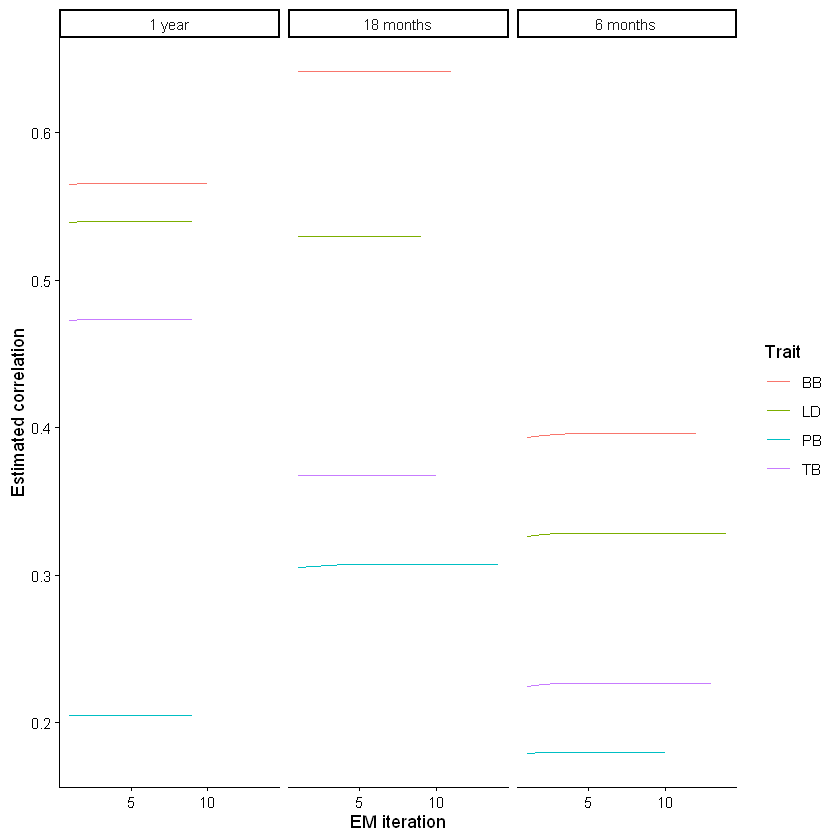

In [6]:
long$residual_final <- long$residual_observed
long$status <- ifelse(!long$eligible, "not_age_eligible",
  ifelse(is.na(long$residual_observed), "missing", "observed")
)
em_models <- list()
traces <- list()
imputation_summary <- list()
for (j in 2:4) for (tr in traits) {
  target <- which(long$stage_index == j & long$trait == tr & long$eligible)
  previous <- long %>% filter(stage_index == j - 1, trait == tr)
  x <- previous$residual_observed[match(long$ID[target], previous$ID)]
  y <- long$residual_observed[target]
  usable <- is.finite(x)
  # Use originally observed residuals as predictors.
  fit <- em_bivariate(x[usable], y[usable])
  uidx <- target[usable]
  fill <- fit$missing
  long$residual_final[uidx[fill]] <- rnorm(sum(fill), fit$prediction[fill], fit$conditional_sd)
  long$status[uidx[fill]] <- "imputed_original_X"
  key <- paste(j, tr, sep = "_")
  em_models[[key]] <- fit
  traces[[key]] <- cbind(stage = stages[j], trait = tr, fit$trace)
  imputation_summary[[key]] <- data.frame(
    stage = stages[j], trait = tr,
    original_pairs = sum(usable & is.finite(y)), imputed = sum(fill),
    remaining = sum(!is.finite(long$residual_final[target])), iterations = nrow(fit$trace),
    em_r = tail(fit$trace$r, 1), conditional_sd = fit$conditional_sd
  )
}
stopifnot(identical(
  long$residual_observed[long$status == "observed"],
  long$residual_final[long$status == "observed"]
))
print(bind_rows(imputation_summary), row.names = FALSE)
write.csv(bind_rows(imputation_summary), file.path(output_dir, "05_imputation_summary.csv"), row.names = FALSE)
write.csv(bind_rows(traces), file.path(output_dir, "06_em_trace.csv"), row.names = FALSE)
write.csv(long, file.path(output_dir, "07_residuals_and_provenance.csv"), row.names = FALSE)
trace_plot <- ggplot(bind_rows(traces), aes(iteration, r, color = trait)) +
  geom_line() +
  facet_wrap(~stage) +
  theme_classic(base_size = 11) +
  labs(x = "EM iteration", y = "Estimated correlation", color = "Trait")
print(trace_plot)
ggsave(file.path(output_dir, "em_trace.pdf"), trace_plot, width = 9, height = 4)


## 6. Analysis cohorts and sample-size checks

Use animals with all four traits available for each within-stage analysis. For across-stage analysis, use the intersection of the complete sets at all four stages. The checks compare the resulting counts with the audited counts.

In [7]:
wide <- long %>%
  select(ID, stage_index, stage, trait, residual_final) %>%
  pivot_wider(names_from = trait, values_from = residual_final)
within_data <- lapply(1:4, function(j) wide %>%
  filter(stage_index == j) %>%
  filter(if_all(all_of(traits), ~ is.finite(.x))))
n_within <- vapply(within_data, nrow, integer(1))
stopifnot(identical(n_within, c(300L, 300L, 248L, 213L)))
common_ids <- Reduce(intersect, lapply(within_data, function(d) d$ID))
stopifnot(length(common_ids) == 213L)
write.csv(data.frame(ID = common_ids), file.path(output_dir, "08_common_213_ID.csv"), row.names = FALSE)
print(data.frame(stage = stages, n = n_within))
cat("Complete IDs across all ages and traits:", length(common_ids), "\n")
across_data <- lapply(traits, function(tr) {
  d <- wide %>%
    filter(ID %in% common_ids) %>%
    select(ID, stage_index, all_of(tr)) %>%
    pivot_wider(names_from = stage_index, values_from = all_of(tr)) %>%
    arrange(ID)
  as.data.frame(d[, as.character(1:4)])
})
names(across_data) <- traits
across_data <- lapply(across_data, function(d) {
  names(d) <- stages
  d
})


      stage   n
1     Birth 300
2  6 months 300
3    1 year 248
4 18 months 213
Complete IDs across all ages and traits: 213 


## 7. Pearson residual correlations and observed-pair comparisons

Report Pearson r, the number of pairs, and how many pairs contain at least one imputed residual. Within each analysis cohort, calculate correlations again using pairs of original residuals. Differences may reflect both sample composition and imputation.

In [8]:
pair_table <- function(d, vars, group, mode) {
  bind_rows(lapply(combn(vars, 2, simplify = FALSE), function(v) {
    ok <- complete.cases(d[, v])
    data.frame(
      mode = mode, group = group, x = v[1], y = v[2],
      n = sum(ok), r = if (sum(ok) > 2) cor(d[ok, v[1]], d[ok, v[2]]) else NA_real_
    )
  }))
}
correlations <- bind_rows(
  bind_rows(lapply(1:4, function(j) pair_table(as.data.frame(within_data[[j]]), traits, stages[j], "within_age"))),
  bind_rows(lapply(traits, function(tr) pair_table(across_data[[tr]], stages, tr, "across_age")))
)
observed_wide <- long %>%
  select(ID, stage_index, trait, residual_observed) %>%
  pivot_wider(names_from = trait, values_from = residual_observed)
comparisons <- list()
for (j in 1:4) {
  d <- observed_wide %>% filter(stage_index == j, ID %in% within_data[[j]]$ID)
  comparisons[[paste0("within", j)]] <- pair_table(as.data.frame(d), traits, stages[j], "within_age")
}
for (tr in traits) {
  d <- long %>%
    filter(trait == tr, ID %in% common_ids) %>%
    select(ID, stage_index, residual_observed) %>%
    pivot_wider(names_from = stage_index, values_from = residual_observed) %>%
    arrange(ID)
  d <- as.data.frame(d[, as.character(1:4)])
  names(d) <- stages
  comparisons[[tr]] <- pair_table(d, stages, tr, "across_age")
}
comparison <- bind_rows(comparisons) %>% rename(n_original_pairs = n, r_original_pairs = r)
correlations <- left_join(correlations, comparison, by = c("mode", "group", "x", "y")) %>%
  mutate(n_pairs_with_imputation = n - n_original_pairs)
stopifnot(nrow(correlations) == 48L, all(is.finite(correlations$r)))
print(tibble::as_tibble(correlations), n = 48)
write.csv(correlations, file.path(output_dir, "09_correlations.csv"), row.names = FALSE)


# A tibble: 48 x 9
   mode       group   x     y         n      r n_original_pairs r_original_pairs
   <chr>      <chr>   <chr> <chr> <int>  <dbl>            <int>            <dbl>
 1 within_age Birth   BB    PB      300 0.334               300           0.334 
 2 within_age Birth   BB    TB      300 0.405               300           0.405 
 3 within_age Birth   BB    LD      300 0.785               300           0.785 
 4 within_age Birth   PB    TB      300 0.277               300           0.277 
 5 within_age Birth   PB    LD      300 0.382               300           0.382 
 6 within_age Birth   TB    LD      300 0.335               300           0.335 
 7 within_age 6 mont~ BB    PB      300 0.486               251           0.614 
 8 within_age 6 mont~ BB    TB      300 0.587               251           0.701 
 9 within_age 6 mont~ BB    LD      300 0.654               251           0.734 
10 within_age 6 mont~ PB    TB      300 0.486               251           0.607 
11 within

## 7A. Manuscript tables

Summarize data availability, original measurements, actual measurement ages, and cohort composition. Percentages of missing and imputed records use age-eligible animals as the denominator. The proportion of initially missing records imputed is reported separately. Descriptive statistics use observed measurements in kg for BB and cm for PB, TB, and LD.

In [9]:
journal_dir <- file.path(output_dir, "journal_tables")
dir.create(journal_dir, showWarnings = FALSE)
sex_label <- function(x) ifelse(as.character(x) == "JANTAN", "Male",
  ifelse(as.character(x) == "BETINA", "Female", as.character(x))
)
trait_names <- c(BB = "Body weight", PB = "Body length", TB = "Withers height", LD = "Chest girth")
# Confirm anatomical definitions and measurement units against the field protocol.
html_escape <- function(x) as.character(htmltools::htmlEscape(as.character(x)))
journal_table <- function(d, filename, caption, note) {
  write.csv(d, file.path(journal_dir, paste0(filename, ".csv")), row.names = FALSE, na = "")
  formatted <- lapply(d, function(x) if (is.numeric(x)) {
    ifelse(is.na(x), "", formatC(x, format = "f", digits = if (all(is.na(x) | x == round(x))) 0 else 2))
  } else ifelse(is.na(x), "", as.character(x)))
  formatted <- as.data.frame(formatted, check.names = FALSE)
  rows <- apply(formatted, 1, function(x) paste0("<tr>", paste0("<td>", html_escape(x), "</td>", collapse = ""), "</tr>"))
  html <- paste0(
    '<div class="journal-table"><table><caption>', html_escape(caption),
    '</caption><thead><tr>', paste0('<th>', html_escape(names(d)), '</th>', collapse = ''),
    '</tr></thead><tbody>', paste(rows, collapse = ''), '</tbody></table><p>', html_escape(note), '</p></div>'
  )
  style <- '<style>.journal-table{font:13px Arial,sans-serif;overflow-x:auto;margin:16px 0}.journal-table table{border-collapse:collapse;width:100%}.journal-table caption{text-align:left;font-weight:bold;padding:8px 0}.journal-table th{border-top:2px solid #222;border-bottom:1px solid #222;padding:6px;text-align:left}.journal-table td{padding:5px 7px;text-align:right;white-space:nowrap}.journal-table td:first-child{text-align:left}.journal-table tbody tr:last-child td{border-bottom:2px solid #222}.journal-table p{font-size:12px;line-height:1.4}</style>'
  writeLines(paste0(
    '<!doctype html><html lang="en"><meta charset="utf-8"><title>',
    html_escape(caption), '</title>', style, html, '</html>'
  ), file.path(journal_dir, paste0(filename, ".html")))
  IRdisplay::display_html(paste0(style, html))
  invisible(d)
}
availability <- long %>%
  group_by(stage_index, stage, trait) %>%
  summarise(
    Eligible = sum(eligible), Observed = sum(eligible & status == "observed"),
    Missing_initial = sum(eligible & is.na(residual_observed)),
    Imputed = sum(status == "imputed_original_X"),
    Missing_remaining = sum(eligible & is.na(residual_final)),
    Available_final = sum(eligible & is.finite(residual_final)), .groups = "drop"
  ) %>%
  mutate(
    Missing_pct = 100 * Missing_initial / Eligible, Imputed_pct = 100 * Imputed / Eligible,
    Missing_imputed_pct = ifelse(Missing_initial > 0, 100 * Imputed / Missing_initial, NA_real_)
  )
stopifnot(
  all(availability$Observed + availability$Missing_initial == availability$Eligible),
  all(availability$Observed + availability$Imputed + availability$Missing_remaining == availability$Eligible)
)
table1 <- availability %>% select(
  Stage = stage, Trait = trait, `Age-eligible, n` = Eligible,
  `Observed, n` = Observed, `Initially missing, n` = Missing_initial, `Initially missing, %` = Missing_pct,
  `Imputed, n` = Imputed, `Imputed, % of eligible` = Imputed_pct,
  `Imputed, % of initially missing` = Missing_imputed_pct,
  `Remaining missing, n` = Missing_remaining, `Available after imputation, n` = Available_final
)
journal_table(
  table1, "Table_1_data_availability", "Table 1. Data availability and imputation by age stage and trait",
  "Eligibility was determined at 30 September 2026. Zero measurements were treated as missing. Imputation used only an observed residual of the same trait at the preceding age stage. An empty percentage denotes no initially missing values."
)
# Statistics on the original measurement scale.
original <- long %>%
  filter(eligible, !is.na(value)) %>%
  mutate(Sex = sex_label(sex))
original_groups <- bind_rows(original, original %>% mutate(Sex = "Overall"))
table2 <- original_groups %>%
  group_by(stage_index, stage, trait, Sex) %>%
  summarise(
    n = n(), Mean = mean(value), SD = sd(value), Minimum = min(value), Maximum = max(value), .groups = "drop"
  ) %>%
  arrange(stage_index, match(trait, traits), match(Sex, c("Overall", "Female", "Male"))) %>%
  select(Stage = stage, Trait = trait, Sex, n, Mean, SD, Minimum, Maximum)
journal_table(
  table2, "Table_2_observed_measurements", "Table 2. Descriptive statistics of observed body measurements",
  "Observed measurements only; imputed residuals are excluded. BB = body weight; PB = body length; TB = withers height; LD = chest girth. BB is expressed in kg; PB, TB and LD are expressed in cm. Confirm anatomical definitions against the field protocol before submission. No nonzero outliers were removed."
)
age_records <- long %>%
  filter(eligible, trait == "BB", !is.na(value)) %>%
  distinct(ID, stage_index, stage, sex, age) %>%
  mutate(Sex = sex_label(sex))
age_groups <- bind_rows(age_records, age_records %>% mutate(Sex = "Overall"))
table3 <- age_groups %>%
  group_by(stage_index, stage, Sex) %>%
  summarise(
    n = n(), `Mean age, days` = mean(age), `SD, days` = sd(age),
    `Minimum age, days` = min(age), `Maximum age, days` = max(age), .groups = "drop"
  ) %>%
  arrange(stage_index, match(Sex, c("Overall", "Female", "Male"))) %>%
  select(-stage_index) %>%
  rename(Stage = stage)
journal_table(
  table3, "Table_3_measurement_age", "Table 3. Actual age at measurement",
  "Each animal is counted once per age stage, using records with observed body weight and a valid measurement date. Age at birth is zero. Nominal age-stage labels do not imply identical measurement ages."
)
cohort_records <- long %>%
  filter(eligible, trait == "BB") %>%
  distinct(ID, stage_index, stage, sex)
composition <- bind_rows(
  cohort_records %>% mutate(Cohort = "Age-eligible"),
  bind_rows(lapply(1:4, function(j) cohort_records %>% filter(stage_index == j, ID %in% within_data[[j]]$ID))) %>%
    mutate(Cohort = "Within-age analysis"),
  cohort_records %>% filter(stage_index == 1, ID %in% common_ids) %>%
    mutate(stage = "All four stages", Cohort = "Across-age complete cohort", stage_index = 5L)
)
table4 <- composition %>%
  mutate(Sex = sex_label(sex)) %>%
  group_by(Cohort, stage_index, stage, Sex) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(Cohort, stage_index, stage) %>%
  mutate(Percentage = 100 * n / sum(n)) %>%
  ungroup() %>%
  arrange(Cohort, stage_index, Sex) %>%
  select(Cohort, Stage = stage, Sex, n, Percentage)
journal_table(
  table4, "Table_4_sample_composition", "Table 4. Sex composition of eligible and analysis cohorts",
  "Percentages are calculated within each cohort and age stage. The across-age cohort contains the same 213 animals with all four traits available at all four stages after imputation."
)
table5 <- long %>%
  filter(ID %in% common_ids) %>%
  group_by(stage_index, stage, trait) %>%
  summarise(
    `Observed, n` = sum(status == "observed"), `Imputed, n` = sum(status == "imputed_original_X"),
    `Imputed, %` = 100 * mean(status == "imputed_original_X"), .groups = "drop"
  ) %>%
  select(Stage = stage, Trait = trait, everything(), -stage_index)
stopifnot(all(table5$`Observed, n` + table5$`Imputed, n` == 213))
journal_table(
  table5, "Table_5_common_cohort_imputation", "Table 5. Contribution of observed and imputed residuals to the across-age cohort",
  "The denominator is 213 animals for every stage–trait combination. Imputed residuals were not reused as predictors."
)
table6 <- long %>%
  filter(status %in% c("observed", "imputed_original_X")) %>%
  mutate(Source = ifelse(status == "observed", "Observed residuals", "Imputed residuals")) %>%
  bind_rows(long %>% filter(is.finite(residual_final)) %>% mutate(Source = "Combined residuals")) %>%
  group_by(stage_index, stage, trait, Source) %>%
  summarise(
    n = n(), Mean = mean(residual_final),
    SD = sd(residual_final), Minimum = min(residual_final), Maximum = max(residual_final), .groups = "drop"
  ) %>%
  arrange(stage_index, match(trait, traits), Source) %>%
  select(Stage = stage, Trait = trait, Source, n, Mean, SD, Minimum, Maximum)
journal_table(
  table6, "Table_S1_residual_summary", "Table S1. Distribution of observed, imputed, and combined residuals",
  "Residuals were obtained from separate linear models for each stage–trait combination. Birth models included sex; subsequent stages included sex and actual age in days. Residual summaries are not raw body measurements."
)
table7 <- correlations %>%
  mutate(Analysis = ifelse(mode == "within_age", "Within age", "Across ages")) %>%
  select(Analysis,
    Group = group, `Variable 1` = x, `Variable 2` = y, n, `Pearson r` = r,
    `Observed pairs, n` = n_original_pairs, `Observed-pair r` = r_original_pairs,
    `Pairs involving imputation, n` = n_pairs_with_imputation
  )
journal_table(
  table7, "Table_6_residual_correlations", "Table 6. Residual correlations and observed-pair comparisons",
  "Within-age analyses use all available animals at each stage; across-age analyses use the same 213 complete animals. Observed-pair comparisons use original residuals within the corresponding analysis cohort. No naive imputation-based significance tests are reported."
)


Your code contains a unicode char which cannot be displayed in your
current locale and R will silently convert it to an escaped form when the
R kernel executes this code. This can lead to subtle errors if you use
such chars to do comparisons. For more information, please see
https://github.com/IRkernel/repr/wiki/Problems-with-unicode-on-windows

Stage,Trait,"Age-eligible, n","Observed, n","Initially missing, n","Initially missing, %","Imputed, n","Imputed, % of eligible","Imputed, % of initially missing","Remaining missing, n","Available after imputation, n"
Birth,BB,300,300,0,0.00,0,0.00,,0,300
Birth,LD,300,300,0,0.00,0,0.00,,0,300
Birth,PB,300,300,0,0.00,0,0.00,,0,300
Birth,TB,300,300,0,0.00,0,0.00,,0,300
6 months,BB,300,251,49,16.33,49,16.33,100.00,0,300
6 months,LD,300,251,49,16.33,49,16.33,100.00,0,300
6 months,PB,300,251,49,16.33,49,16.33,100.00,0,300
6 months,TB,300,251,49,16.33,49,16.33,100.00,0,300
1 year,BB,282,220,62,21.99,28,9.93,45.16,34,248
1 year,LD,282,220,62,21.99,28,9.93,45.16,34,248


Stage,Trait,Sex,n,Mean,SD,Minimum,Maximum
Birth,BB,Overall,300,19.24,3.16,11.50,28.00
Birth,BB,Female,158,18.22,2.95,11.50,28.00
Birth,BB,Male,142,20.36,3.00,14.00,27.00
Birth,PB,Overall,300,51.97,3.19,42.00,65.00
Birth,PB,Female,158,51.43,3.21,42.00,63.00
Birth,PB,Male,142,52.56,3.07,45.00,65.00
Birth,TB,Overall,300,64.59,5.67,42.00,75.00
Birth,TB,Female,158,63.82,5.56,45.00,74.00
Birth,TB,Male,142,65.44,5.68,42.00,75.00
Birth,LD,Overall,300,61.40,4.14,45.00,73.00


Stage,Sex,n,"Mean age, days","SD, days","Minimum age, days","Maximum age, days"
Birth,Overall,300,0.00,0.00,0,0
Birth,Female,158,0.00,0.00,0,0
Birth,Male,142,0.00,0.00,0,0
6 months,Overall,251,206.68,8.90,189,226
6 months,Female,133,206.91,8.74,189,226
6 months,Male,118,206.42,9.11,189,221
1 year,Overall,220,365.34,8.81,348,380
1 year,Female,113,365.00,8.70,348,380
1 year,Male,107,365.69,8.94,348,380
18 months,Overall,170,541.22,9.40,523,557


Cohort,Stage,Sex,n,Percentage
Across-age complete cohort,All four stages,Female,111,52.11
Across-age complete cohort,All four stages,Male,102,47.89
Age-eligible,Birth,Female,158,52.67
Age-eligible,Birth,Male,142,47.33
Age-eligible,6 months,Female,158,52.67
Age-eligible,6 months,Male,142,47.33
Age-eligible,1 year,Female,144,51.06
Age-eligible,1 year,Male,138,48.94
Age-eligible,18 months,Female,133,52.78
Age-eligible,18 months,Male,119,47.22


Stage,Trait,"Observed, n","Imputed, n","Imputed, %"
Birth,BB,213,0,0.00
Birth,LD,213,0,0.00
Birth,PB,213,0,0.00
Birth,TB,213,0,0.00
6 months,BB,201,12,5.63
6 months,LD,201,12,5.63
6 months,PB,201,12,5.63
6 months,TB,201,12,5.63
1 year,BB,209,4,1.88
1 year,LD,209,4,1.88


Stage,Trait,Source,n,Mean,SD,Minimum,Maximum
Birth,BB,Combined residuals,300,-0.00,2.97,-6.72,9.78
Birth,BB,Observed residuals,300,-0.00,2.97,-6.72,9.78
Birth,PB,Combined residuals,300,-0.00,3.14,-9.43,12.44
Birth,PB,Observed residuals,300,-0.00,3.14,-9.43,12.44
Birth,TB,Combined residuals,300,0.00,5.61,-23.44,10.18
Birth,TB,Observed residuals,300,0.00,5.61,-23.44,10.18
Birth,LD,Combined residuals,300,-0.00,4.05,-17.28,10.72
Birth,LD,Observed residuals,300,-0.00,4.05,-17.28,10.72
6 months,BB,Combined residuals,300,-1.29,24.82,-67.10,66.90
6 months,BB,Imputed residuals,49,-7.90,22.85,-67.10,35.01


Analysis,Group,Variable 1,Variable 2,n,Pearson r,"Observed pairs, n",Observed-pair r,"Pairs involving imputation, n"
Within age,Birth,BB,PB,300,0.33,300,0.33,0
Within age,Birth,BB,TB,300,0.40,300,0.40,0
Within age,Birth,BB,LD,300,0.79,300,0.79,0
Within age,Birth,PB,TB,300,0.28,300,0.28,0
Within age,Birth,PB,LD,300,0.38,300,0.38,0
Within age,Birth,TB,LD,300,0.34,300,0.34,0
Within age,6 months,BB,PB,300,0.49,251,0.61,49
Within age,6 months,BB,TB,300,0.59,251,0.70,49
Within age,6 months,BB,LD,300,0.65,251,0.73,49
Within age,6 months,PB,TB,300,0.49,251,0.61,49


## 7B. Sensitivity to stochastic imputation draws

Generate 20 additional draws with different seeds and fixed EM parameters. Keep the analysis cohorts and missingness patterns fixed. The resulting ranges describe Monte Carlo variation conditional on the fitted models.

In [10]:
sensitivity <- list()
for (rep in 1:20) {
  set.seed(seed + rep)
  trial <- long
  trial$residual_trial <- trial$residual_observed
  for (j in 2:4) for (tr in traits) {
    target <- which(trial$stage_index == j & trial$trait == tr & trial$eligible)
    previous <- trial %>% filter(stage_index == j - 1, trait == tr)
    x <- previous$residual_observed[match(trial$ID[target], previous$ID)]
    usable <- is.finite(x)
    fit <- em_models[[paste(j, tr, sep = "_")]]
    fill <- !is.finite(trial$residual_observed[target[usable]])
    trial$residual_trial[target[usable][fill]] <- rnorm(sum(fill), fit$prediction[fill], fit$conditional_sd)
  }
  tw <- trial %>%
    select(ID, stage_index, trait, residual_trial) %>%
    pivot_wider(names_from = trait, values_from = residual_trial)
  results <- list()
  for (j in 1:4) results[[paste0("within", j)]] <- pair_table(
    as.data.frame(tw %>% filter(stage_index == j, ID %in% within_data[[j]]$ID)), traits, stages[j], "within_age"
  )
  for (tr in traits) {
    d <- tw %>%
      filter(ID %in% common_ids) %>%
      select(ID, stage_index, all_of(tr)) %>%
      pivot_wider(names_from = stage_index, values_from = all_of(tr)) %>%
      arrange(ID)
    d <- as.data.frame(d[, as.character(1:4)])
    names(d) <- stages
    results[[tr]] <- pair_table(d, stages, tr, "across_age")
  }
  sensitivity[[rep]] <- bind_rows(results) %>% mutate(Repeat = rep)
}
set.seed(seed) # Primary imputation and all downstream figures remain unchanged.
sensitivity_runs <- bind_rows(sensitivity)
stopifnot(nrow(sensitivity_runs) == 20L * 48L, all(is.finite(sensitivity_runs$r)))
table_s2 <- sensitivity_runs %>%
  group_by(mode, group, x, y) %>%
  summarise(
    `Repeats, n` = n(), `Mean r` = mean(r), `SD of r` = sd(r), `Minimum r` = min(r), `Maximum r` = max(r), .groups = "drop"
  ) %>%
  mutate(Analysis = ifelse(mode == "within_age", "Within age", "Across ages")) %>%
  select(Analysis, Group = group, `Variable 1` = x, `Variable 2` = y, everything(), -mode)
journal_table(
  table_s2, "Table_S2_imputation_stability", "Table S2. Monte Carlo stability of residual correlations across 20 stochastic imputations",
  "EM parameters were held fixed. The range is a simulation range, not a confidence interval. This assessment excludes parameter uncertainty, linear-model estimation uncertainty, and violations of missingness or distributional assumptions."
)
write.csv(sensitivity_runs, file.path(output_dir, "11_imputation_stability_runs.csv"), row.names = FALSE)


Analysis,Group,Variable 1,Variable 2,"Repeats, n",Mean r,SD of r,Minimum r,Maximum r
Across ages,BB,1 year,18 months,20,0.63,0.02,0.59,0.66
Across ages,BB,6 months,1 year,20,0.55,0.01,0.51,0.57
Across ages,BB,6 months,18 months,20,0.45,0.02,0.41,0.48
Across ages,BB,Birth,1 year,20,0.36,0.01,0.34,0.37
Across ages,BB,Birth,18 months,20,0.27,0.02,0.23,0.30
Across ages,BB,Birth,6 months,20,0.40,0.01,0.37,0.43
Across ages,LD,1 year,18 months,20,0.52,0.02,0.48,0.59
Across ages,LD,6 months,1 year,20,0.51,0.02,0.47,0.54
Across ages,LD,6 months,18 months,20,0.40,0.02,0.35,0.45
Across ages,LD,Birth,1 year,20,0.31,0.01,0.29,0.33


## 8. GGally correlation figures

Figure 1 contains four within-stage matrices. Figure 2 contains four across-stage matrices for the 213-animal cohort. Each matrix shows scatterplots below the diagonal, residual densities on the diagonal, and Pearson coefficients above it. Significance symbols represent nominal two-sided Pearson tests on completed data and omit imputation uncertainty. Export both figures as vector PDFs and 400 dpi PNGs.

[GGally documentation](https://ggobi.github.io/ggally/reference/ggpairs.html)

The two previews below were rendered from the saved residual dataset used for the manuscript. Running the plotting cell uses the residuals calculated in the active notebook session.

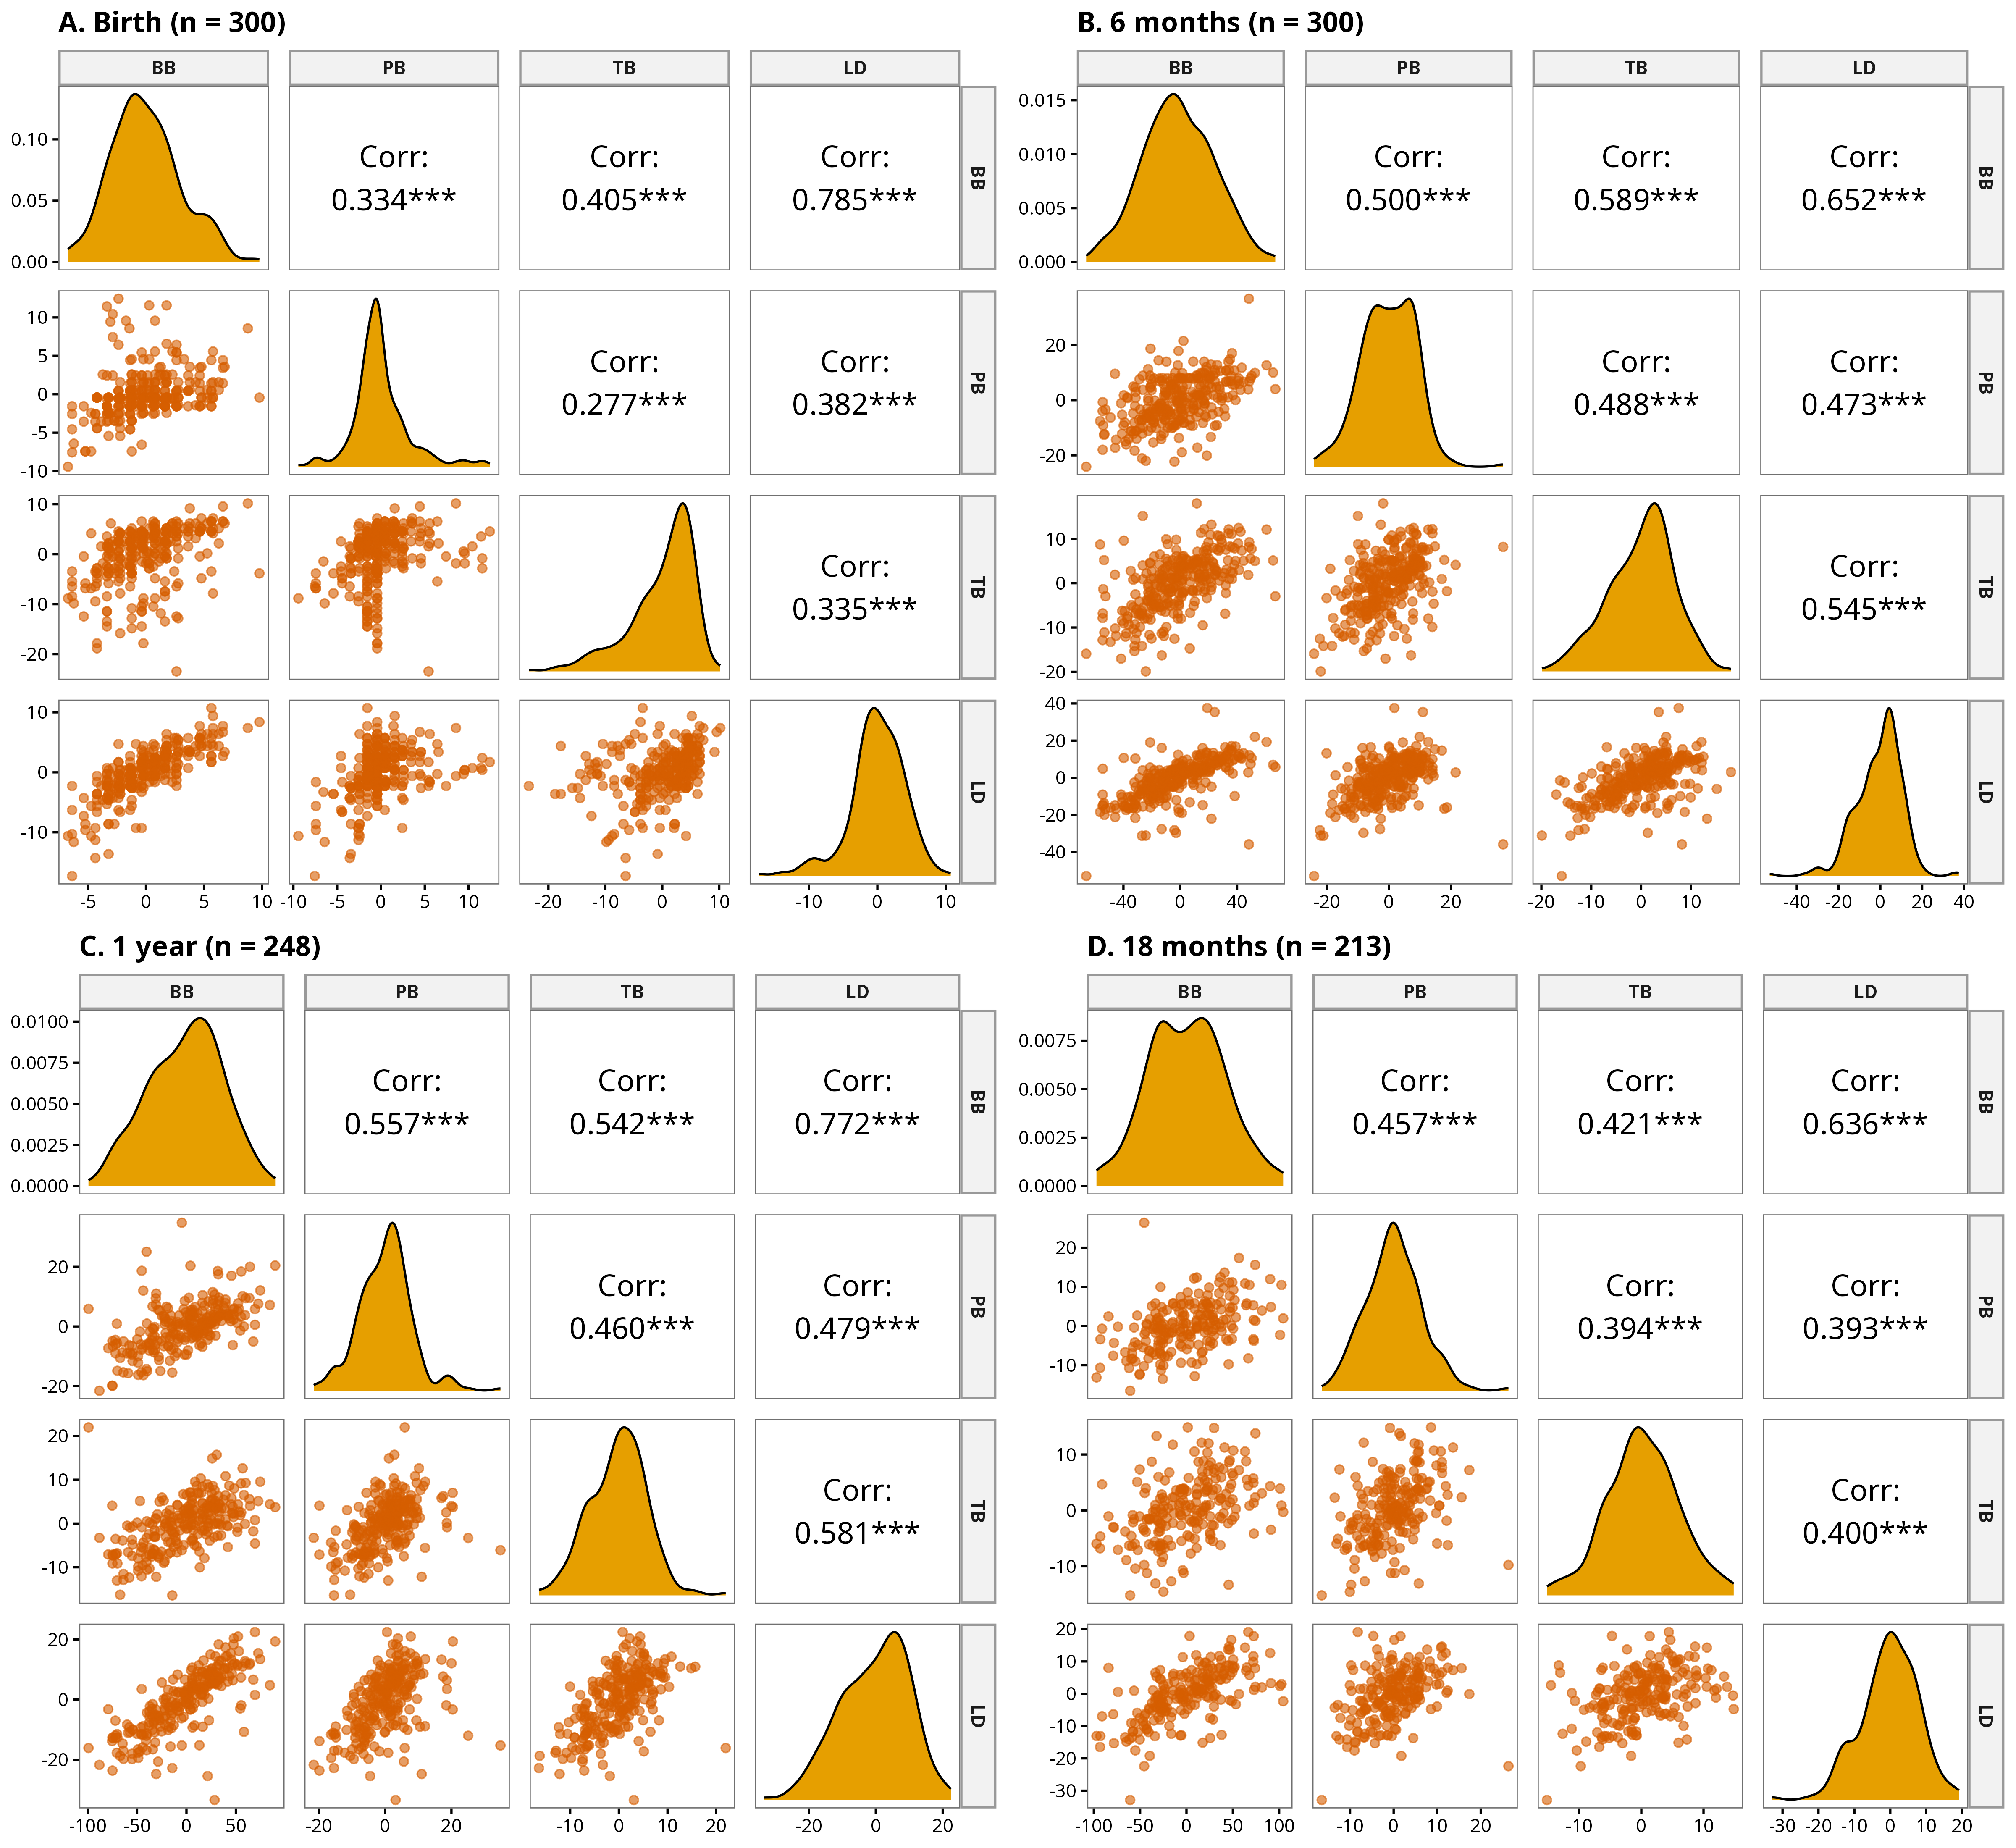

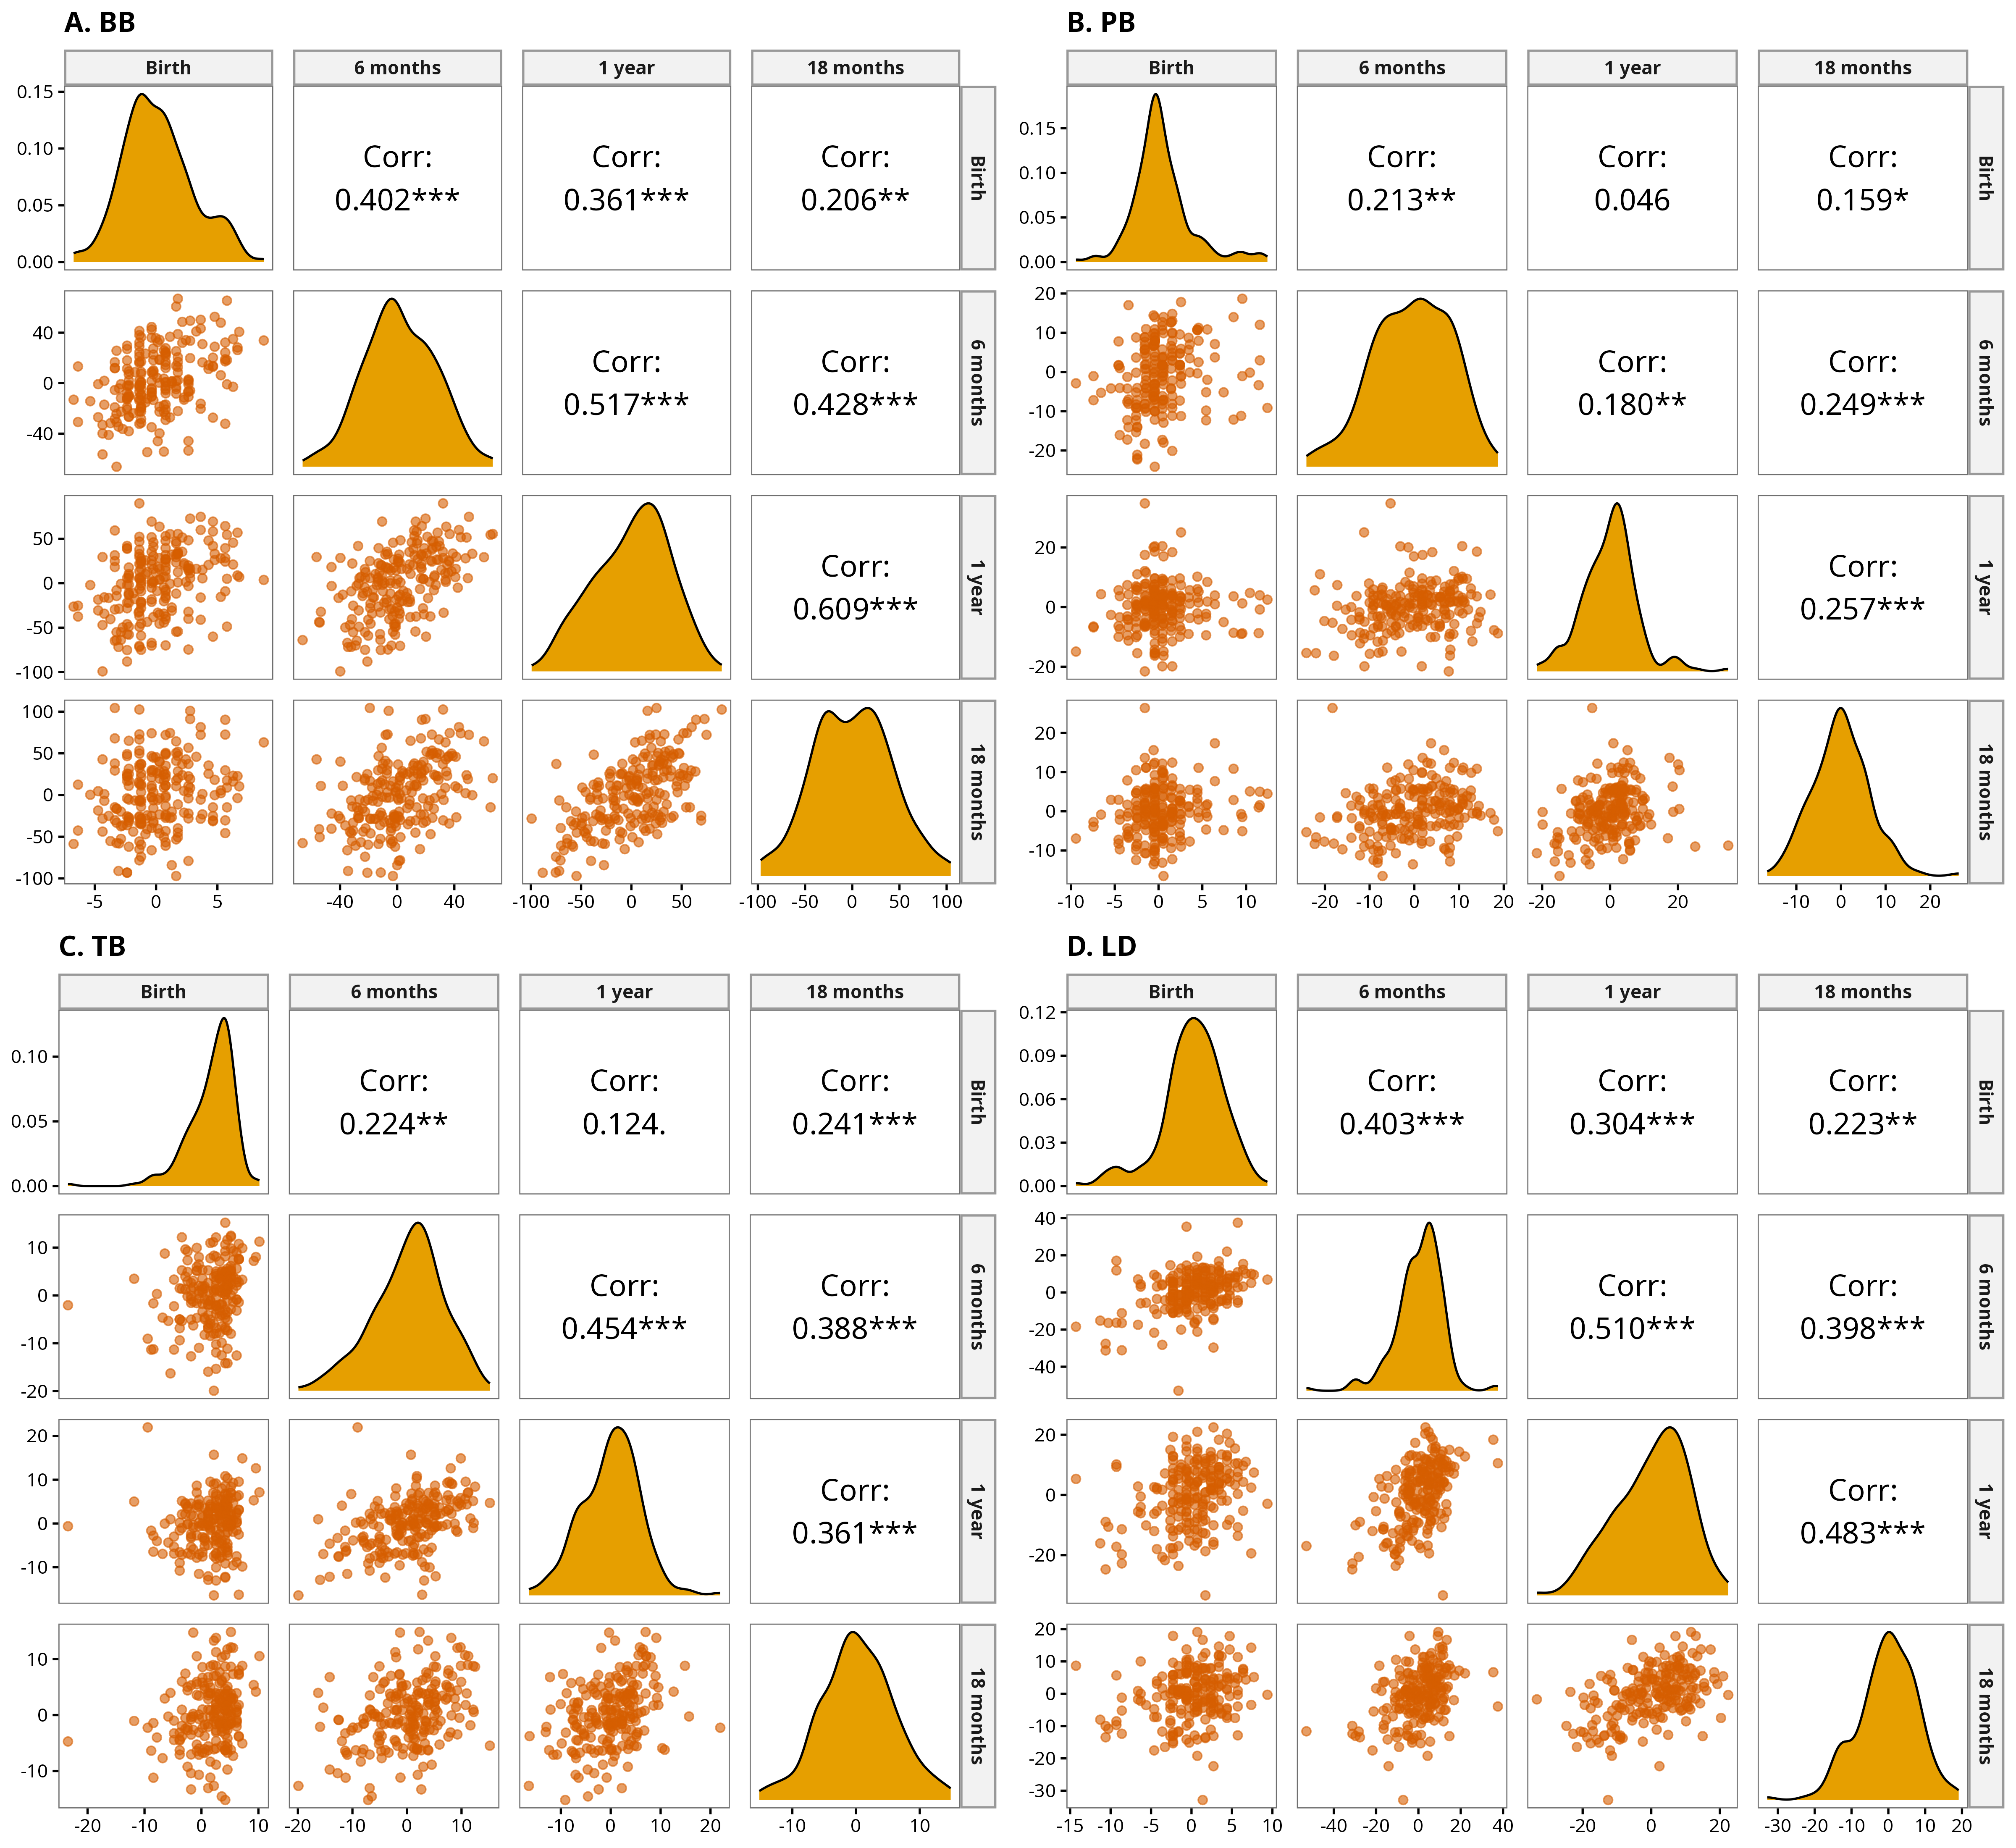

In [ ]:
make_matrix <- function(d, title) {
  GGally::ggpairs(
    d,
    columns = 1:4, title = title, progress = FALSE,
    lower = list(
      continuous = GGally::wrap(
        "points",
        alpha = 0.6, size = 1.5, colour = "#D55E00"
      )
    ),
    diag = list(
      continuous = GGally::wrap(
        "densityDiag",
        fill = "#E69F00"
      )
    ),
    upper = list(
      continuous = GGally::wrap(
        "cor",
        size = 4.5, colour = "black", stars = TRUE
      )
    )
  ) +
    theme_classic(base_size = 10, base_family = "sans") +
    theme(
      strip.background = element_rect(fill = "grey95", color = "grey60"),
      strip.text = element_text(face = "bold"),
      plot.title = element_text(size = 12, face = "bold"),
      axis.text = element_text(size = 8),
      panel.border = element_rect(
        colour = "#707070", fill = NA, linewidth = .45
      ),
      axis.line = element_blank(),
      panel.spacing = grid::unit(3, "mm")
    )
}

compose_figure <- function(data, labels) {
  matrices <- Map(make_matrix, data, paste0(LETTERS[1:4], ". ", labels))
  gridExtra::arrangeGrob(grobs = lapply(matrices, GGally::ggmatrix_gtable), ncol = 2)
}
figure_1 <- compose_figure(
  lapply(within_data, function(d) as.data.frame(d[, traits])),
  sprintf("%s (n = %d)", stages, n_within)
)
figure_2 <- compose_figure(across_data, traits)
for (i in 1:2) {
  figure <- list(figure_1, figure_2)[[i]]
  for (ext in c("png", "pdf")) {
    ggsave(file.path(output_dir, sprintf("Figure_%d.%s", i, ext)), figure,
      width = 12, height = 11, units = "in", dpi = 400, bg = "white"
    )
  }
  grid::grid.newpage()
  grid::grid.draw(figure)
}


## 9. Observed and imputed distributions and reproducibility records

Review residual distributions, flagged observations, linear model diagnostics, and the EM convergence trace alongside the descriptive correlations.

Selesai. Hasil disimpan di: C:\Users\rizal\Nextcloud2\PDU_Julius/hasil_korelasi 


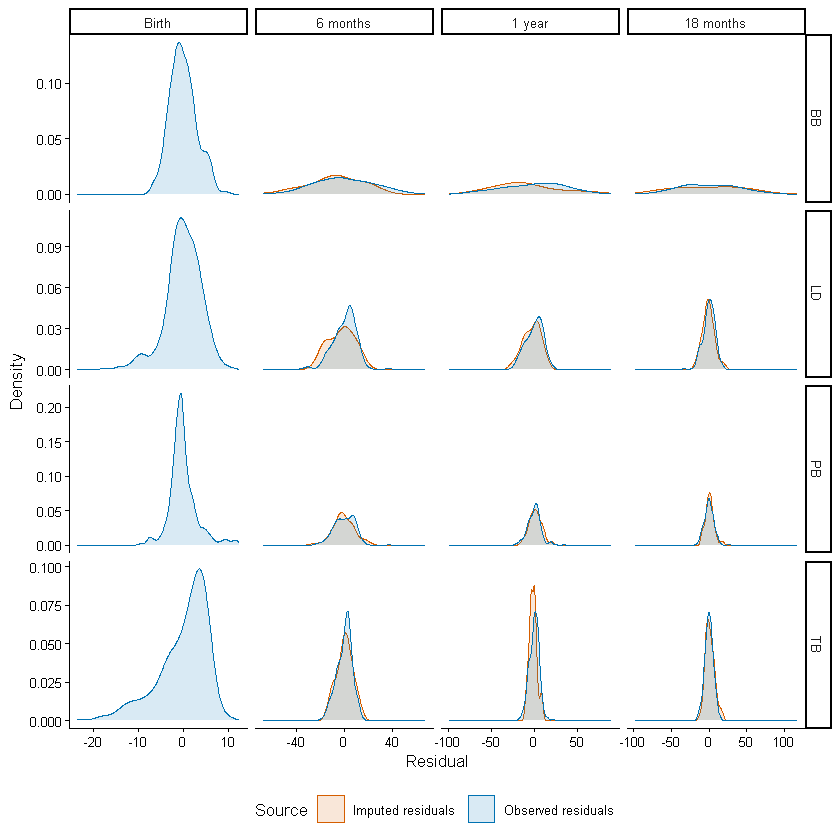

In [12]:
distribution <- long %>%
  filter(status %in% c("observed", "imputed_original_X")) %>%
  mutate(stage = factor(stage, levels = stages))
distribution_plot <- ggplot(distribution, aes(residual_final, color = status, fill = status)) +
  geom_density(alpha = .15) +
  facet_grid(trait ~ stage, scales = "free") +
  scale_color_manual(values = c(imputed_original_X = "#D55E00", observed = "#0072B2"), labels = c(imputed_original_X = "Imputed residuals", observed = "Observed residuals")) +
  scale_fill_manual(values = c(imputed_original_X = "#D55E00", observed = "#0072B2"), labels = c(imputed_original_X = "Imputed residuals", observed = "Observed residuals")) +
  theme_classic(base_size = 10) +
  theme(legend.position = "bottom") +
  labs(x = "Residual", y = "Density", color = "Source", fill = "Source")
print(distribution_plot)
ggsave(file.path(output_dir, "residual_distributions.pdf"), distribution_plot, width = 11, height = 9)
stopifnot(identical(unname(source_hash), unname(tools::md5sum(source_file))))
saveRDS(
  list(
    settings = list(cutoff = cutoff, seed = seed, source_md5 = source_hash),
    models = models, em_models = em_models, data = long, common_ids = common_ids, correlations = correlations
  ),
  file.path(output_dir, "analysis_objects.rds")
)
writeLines(c(
  paste("cutoff:", cutoff), paste("seed:", seed), paste("source_md5:", source_hash),
  "Single stochastic imputation after bivariate-normal EM; original X only; no chaining.",
  "Descriptive residual correlations; no naive imputation-based p-values or confidence intervals.",
  capture.output(sessionInfo())
), file.path(output_dir, "10_reproducibility.txt"))
cat("Selesai. Hasil disimpan di:", output_dir, "\n")


In [16]:
print(within_data[[2]])


# A tibble: 300 x 7
   ID    stage_index stage        BB     PB      TB     LD
   <chr>       <int> <chr>     <dbl>  <dbl>   <dbl>  <dbl>
 1 J0401           2 6 months -32.1  -18.3  -14.2   -14.1 
 2 J1101           2 6 months -29.1   -7.11  -7.13   -7.18
 3 1006            2 6 months -31.7  -11.2  -12.7   -21.7 
 4 1108            2 6 months  -1.43  -4.13  -3.98   -2.99
 5 1039            2 6 months  -4.79 -25.5   -5.69    2.73
 6 I0506           2 6 months -66.2  -24.1  -15.9   -52.9 
 7 1027            2 6 months  36.4   17.0    0.949  14.7 
 8 1001            2 6 months -24.3  -22.0  -19.9   -31.2 
 9 I0607           2 6 months -54.6  -18.0   -7.86   -9.10
10 1005            2 6 months  -4.10 -22.3  -12.6   -28.2 
# i 290 more rows


## Notes for a planned follow-up analysis

1. Fit `y ~ sex` for each trait and retain the residuals.
2. Use the resulting residuals as outcomes and predictors for the correlation analysis and two general linear models. Fit `y ~ x1 + x2 + ... + xn` and `y ~ tail_shape + x1 + x2 + ... + xn`.
